Praktikum 1 - Exploratory Data Analysis (EDA) dataset Titanic.

Alur: muat data -> inspeksi (dimensi, tipe, missing, statistik) ->
inspeksi visual (histogram, boxplot, bar, heatmap, scatter).
Semua grafik disimpan di output/.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("eda_titanic.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js02-pemahaman-data-dan-pra-pengolahan-data\praktikum-1


In [2]:
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

BASE = Path(__file__).resolve().parent
DATA = BASE.parent / "data" / "Titanic-Dataset.csv"
OUT = BASE / "output"
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# ---------- Langkah 1: memuat data ----------
df = pd.read_csv(DATA)
print("=== 5 data pertama ===")
print(df.head().to_string())

=== 5 data pertama ===
   PassengerId  Survived  Pclass                                                 Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
0            1         0       3                              Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
1            2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Thayer)  female  38.0      1      0          PC 17599  71.2833   C85        C
2            3         1       3                               Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
3            4         1       1         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803  53.1000  C123        S
4            5         0       3                             Allen, Mr. William Henry    male  35.0      0      0            373450   8.0500   NaN        S


In [4]:
# ---------- Langkah 2: inspeksi data ----------
print("\n=== Dimensi (baris, kolom) ===")
print(df.shape)

print("\n=== Tipe data ===")
print(df.dtypes.to_string())

missing = df.isnull().sum()
print("\n=== Jumlah missing value per kolom ===")
print(missing[missing > 0].to_string())
print(f"Total missing: {int(missing.sum())} dari {df.size} sel "
      f"({missing.sum() / df.size * 100:.2f}%)")
missing.to_frame("missing").assign(persen=lambda d: d["missing"] / len(df) * 100).to_csv(
    OUT / "missing_value.csv"
)

desc = df.describe()
print("\n=== Statistik deskriptif (numerik) ===")
print(desc.round(3).to_string())
desc.round(4).to_csv(OUT / "statistik_deskriptif.csv")

num_cols = ["Age", "Fare"]
print("\n=== Kemencengan (skewness) ===")
print(df[num_cols].skew().round(3).to_string())


=== Dimensi (baris, kolom) ===
(891, 12)

=== Tipe data ===
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object

=== Jumlah missing value per kolom ===
Age         177
Cabin       687
Embarked      2
Total missing: 866 dari 10692 sel (8.10%)

=== Statistik deskriptif (numerik) ===
       PassengerId  Survived   Pclass      Age    SibSp    Parch     Fare
count      891.000   891.000  891.000  714.000  891.000  891.000  891.000
mean       446.000     0.384    2.309   29.699    0.523    0.382   32.204
std        257.354     0.487    0.836   14.526    1.103    0.806   49.693
min          1.000     0.000    1.000    0.420    0.000    0.000    0.000
25%        223.500     0.000    2.000   20.125    0.000    0.000    7.910
50%        446.000     0.000    3.000   28.000   

In [5]:
# Outlier Fare dengan aturan IQR
q1, q3 = df["Fare"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = int(((df["Fare"] < lo) | (df["Fare"] > hi)).sum())
print(f"\nFare: Q1={q1:.2f} Q3={q3:.2f} IQR={iqr:.2f} batas=[{lo:.2f}, {hi:.2f}] "
      f"outlier={n_out} ({n_out / len(df) * 100:.2f}%)")


Fare: Q1=7.91 Q3=31.00 IQR=23.09 batas=[-26.72, 65.63] outlier=116 (13.02%)


In [6]:
# ---------- Langkah 3: inspeksi visual ----------
# 3a. distribusi numerik
for col in num_cols:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(df[col].dropna(), bins=30)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frekuensi")
    fig.tight_layout()
    fig.savefig(OUT / f"hist_{col.lower()}.png", dpi=110)
    plt.close(fig)

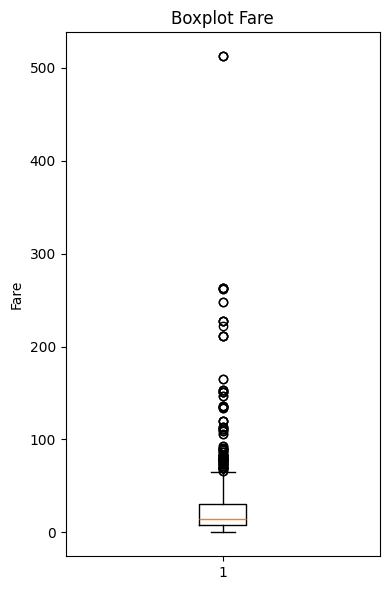

In [7]:
# 3b. outlier Fare
fig, ax = plt.subplots(figsize=(4, 6))
ax.boxplot(df["Fare"].dropna(), vert=True)
ax.set_title("Boxplot Fare")
ax.set_ylabel("Fare")
fig.tight_layout()
fig.savefig(OUT / "boxplot_fare.png", dpi=110)


=== Komposisi variabel kategorikal (value_counts) ===
-- Survived
Survived
0    549
1    342
-- Pclass
Pclass
3    491
1    216
2    184
-- Sex
Sex
male      577
female    314
-- Embarked
Embarked
S      644
C      168
Q       77
NaN      2


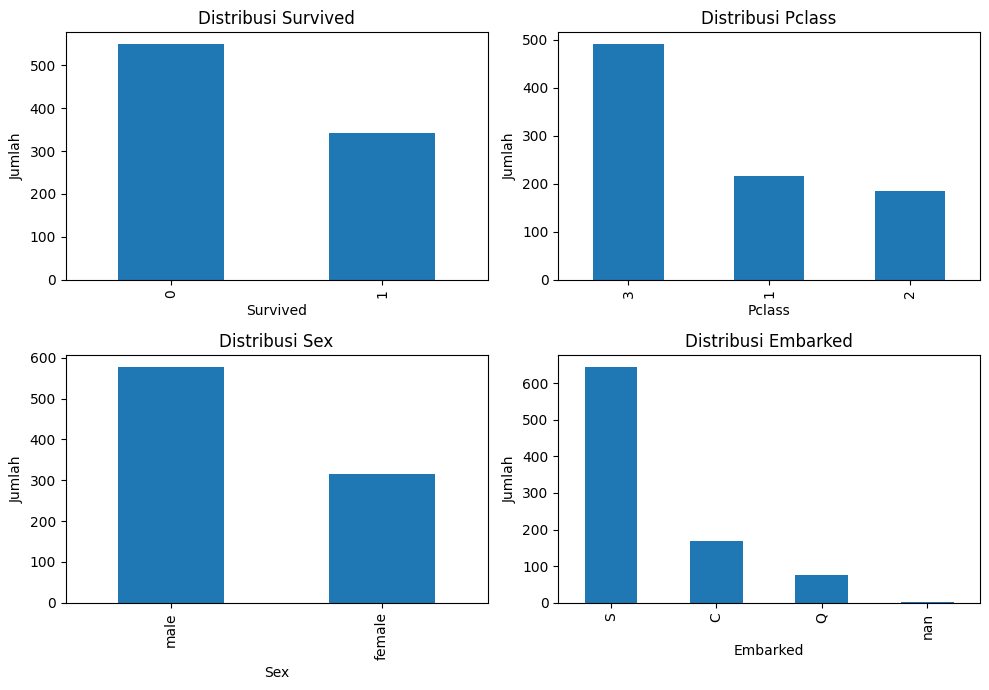

In [8]:
# 3c. komposisi kategorikal
cat_cols = ["Survived", "Pclass", "Sex", "Embarked"]
print("\n=== Komposisi variabel kategorikal (value_counts) ===")
for col in cat_cols:
    print(f"-- {col}")
    print(df[col].value_counts(dropna=False).to_string())

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flatten(), cat_cols):
    df[col].value_counts(dropna=False).plot(kind="bar", ax=ax)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Jumlah")
fig.tight_layout()
fig.savefig(OUT / "bar_kategorikal.png", dpi=110)


=== Korelasi terhadap Survived ===
Survived       1.000
Fare           0.257
Parch          0.082
PassengerId   -0.005
SibSp         -0.035
Age           -0.077
Pclass        -0.338


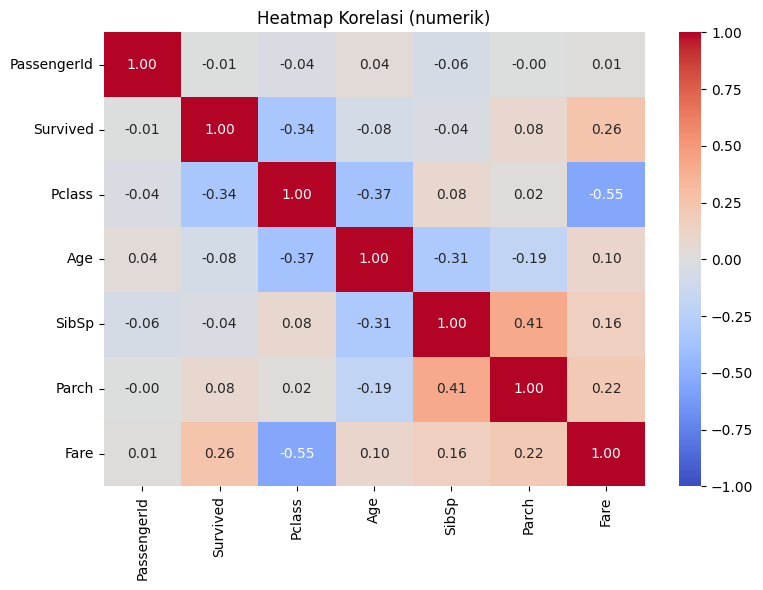

In [9]:
# 3d. heatmap korelasi numerik
num_only = df.select_dtypes(include=[np.number])
corr = num_only.corr(numeric_only=True)
print("\n=== Korelasi terhadap Survived ===")
print(corr["Survived"].sort_values(ascending=False).round(3).to_string())
corr.round(4).to_csv(OUT / "korelasi.csv")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".2f", ax=ax)
ax.set_title("Heatmap Korelasi (numerik)")
fig.tight_layout()
fig.savefig(OUT / "heatmap_korelasi.png", dpi=110)


Korelasi Age-Fare: 0.096
Grafik tersimpan di: C:\code\pemmes26\js02-pemahaman-data-dan-pra-pengolahan-data\praktikum-1\output


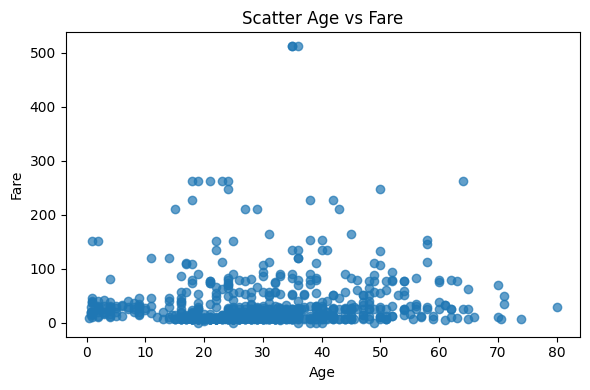

In [10]:
# 3e. scatter Age vs Fare
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["Age"], df["Fare"], alpha=0.7)
ax.set_xlabel("Age")
ax.set_ylabel("Fare")
ax.set_title("Scatter Age vs Fare")
fig.tight_layout()
fig.savefig(OUT / "scatter_age_fare.png", dpi=110)

print(f"\nKorelasi Age-Fare: {df['Age'].corr(df['Fare']):.3f}")
print("Grafik tersimpan di:", OUT)